# 01. Failure-pattern frequency analysis

This notebook counts which governance failure types dominate in the Atlas, and how they split by sector, agent type, and the three authority questions (authorize, prove, revoke).

**Read this first.** The 20 records currently in `data/` are illustrative composites (`seed: true`). The charts below show how to run the analysis. They are not findings about the real world. When community contributions arrive, filter to `seed == False` (a switch is provided in the first code cell) and the same notebook produces real numbers.

Code in this notebook is MIT licensed. The data is CC-BY-4.0. See `LICENSE-NOTE.md`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

# Set to True to analyse only community submissions once they exist.
COMMUNITY_ONLY = False

taxonomy = json.loads((ROOT / "schema" / "taxonomy.json").read_text(encoding="utf-8"))
NAME = {t["tag"]: t["name"] for t in taxonomy["failure_types"]}
LENS = {t["tag"]: t["lens"] for t in taxonomy["failure_types"]}
ALL_TAGS = [t["tag"] for t in taxonomy["failure_types"]]

records = json.loads((ROOT / "data" / "atlas.json").read_text(encoding="utf-8"))
df = pd.DataFrame(
    {
        "id": r["id"],
        "seed": r["seed"],
        "sector": r["sector"],
        "agent_type": r["agent_type"],
        "autonomy": r["autonomy_level"],
        "primary": r["primary_failure_type"],
        "tags": r["failure_types"],
        "severity": r["business_impact"]["severity"],
        "control": r["governance_gap"]["control_category"],
        "time_to_detect": r["detection"]["time_to_detect"],
    }
    for r in records
)
if COMMUNITY_ONLY:
    df = df[~df["seed"]]

df["lens"] = df["primary"].map(LENS)
print(f"{len(df)} records, {df['seed'].sum()} of them seed data")

# Chart style: one hue, recessive axes, direct value labels.
BLUE, INK, MUTED = "#2F6B9A", "#1f2933", "#6b7280"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110,
})

20 records, 20 of them seed data


## 1. Which failure types dominate

Each record has one **primary** type, the control whose absence mattered most. Counting primaries avoids double counting. Types with zero records are kept in the chart on purpose, because an empty row tells you where the data is thin.

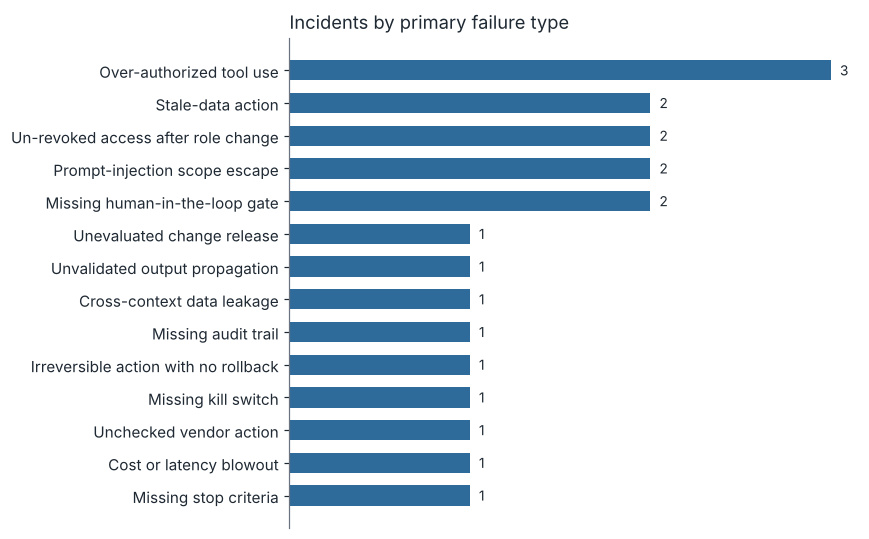

In [2]:
counts = df["primary"].value_counts().reindex(ALL_TAGS, fill_value=0).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([NAME[t] for t in counts.index], counts.values, color=BLUE, height=0.62)
for y, v in enumerate(counts.values):
    ax.text(v + 0.05, y, str(v), va="center", fontsize=9, color=INK)
ax.set_title("Incidents by primary failure type", loc="left", fontsize=12, color=INK)
ax.set_xlabel("Incidents")
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
fig.tight_layout()

(ROOT / "notebooks" / "figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "notebooks" / "figures" / "primary_failure_types.png", dpi=150)
plt.show()

## 2. The three questions: authorize, prove, revoke

Every failure type maps to one of three questions an organization must answer before an agent acts. This groups the 14 types into something a governance committee can discuss in one slide.

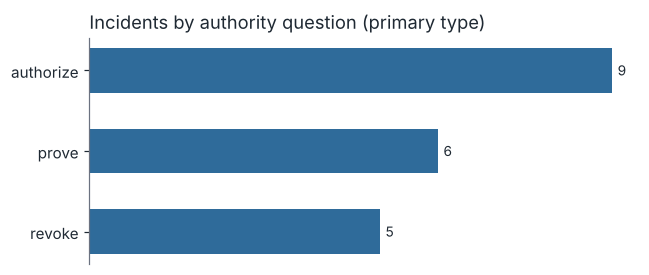

In [3]:
lens_counts = df["lens"].value_counts().reindex(["authorize", "prove", "revoke"], fill_value=0)

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(lens_counts.index[::-1], lens_counts.values[::-1], color=BLUE, height=0.55)
for y, v in enumerate(lens_counts.values[::-1]):
    ax.text(v + 0.1, y, str(v), va="center", fontsize=9, color=INK)
ax.set_title("Incidents by authority question (primary type)", loc="left", fontsize=12, color=INK)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Failure type by sector and by agent type

Heatmaps with counts printed in each cell. With only 20 illustrative records most cells are 0 or 1. The structure is what matters here: once real data arrives, rows that stay dark across sectors point to systemic gaps, and rows that concentrate in one sector point to sector-specific ones.

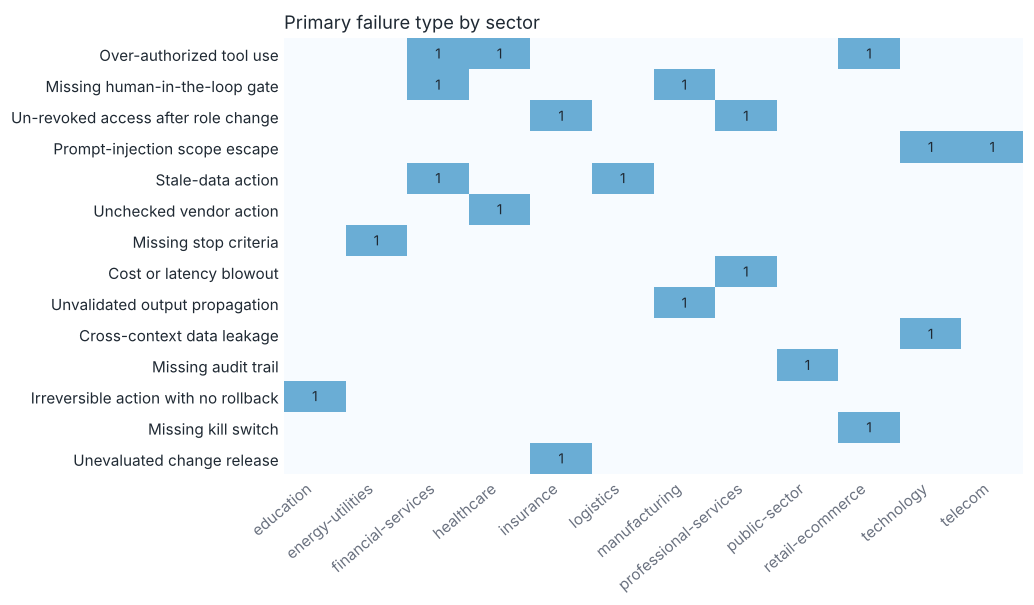

In [4]:
def heatmap(table, title, figsize):
    table = table.reindex(ALL_TAGS, fill_value=0)
    table.index = [NAME[t] for t in table.index]
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(table.values, cmap="Blues", vmin=0, vmax=max(2, table.values.max()), aspect="auto")
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=40, ha="right")
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            if v:
                ax.text(j, i, str(v), ha="center", va="center", fontsize=9,
                        color="white" if v >= 2 else INK)
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    fig.tight_layout()
    plt.show()

heatmap(pd.crosstab(df["primary"], df["sector"]), "Primary failure type by sector", (9.5, 5.6))

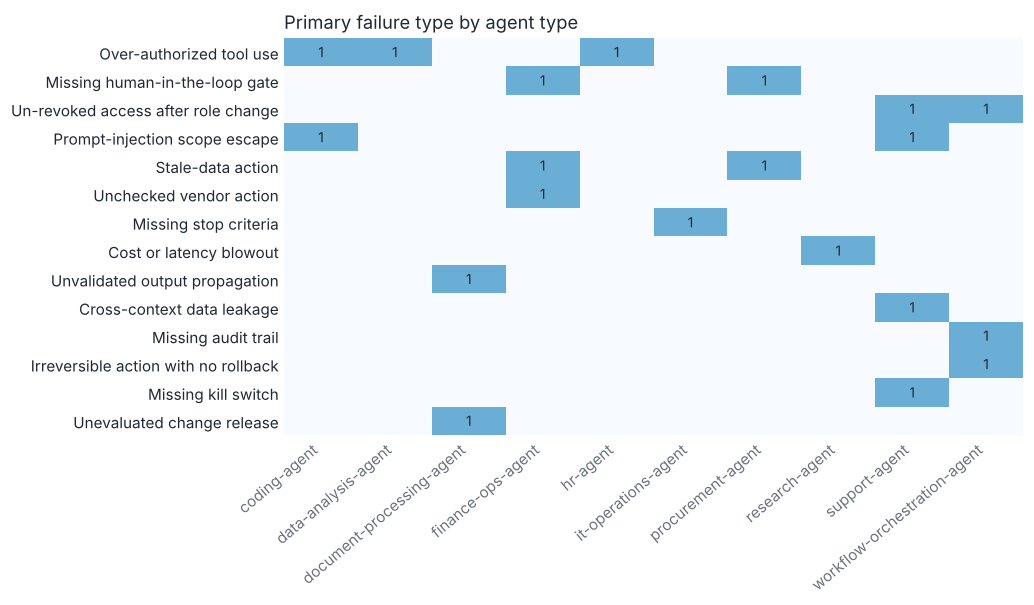

In [5]:
heatmap(pd.crosstab(df["primary"], df["agent_type"]), "Primary failure type by agent type", (9.5, 5.6))

## 4. Which controls were missing

`governance_gap.control_category` groups the missing controls into eleven families. This is the view an audit team uses to decide which control to test first.

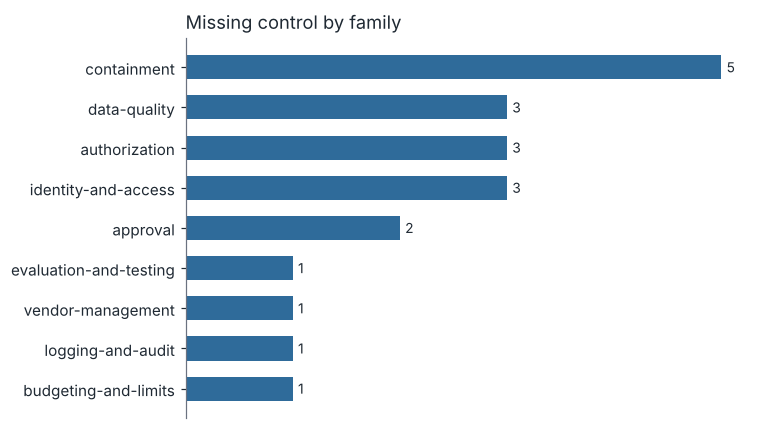

In [6]:
ctrl = df["control"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(ctrl.index, ctrl.values, color=BLUE, height=0.6)
for y, v in enumerate(ctrl.values):
    ax.text(v + 0.05, y, str(v), va="center", fontsize=9, color=INK)
ax.set_title("Missing control by family", loc="left", fontsize=12, color=INK)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
fig.tight_layout()
plt.show()

## 5. Tags that travel together

Secondary tags show which missing controls tend to appear in the same incident. Pairs that recur are candidates for a combined control, for example a gate that handles both approval and rollback.

In [7]:
from collections import Counter
from itertools import combinations

pairs = Counter()
for tags in df["tags"]:
    for a, b in combinations(sorted(tags), 2):
        pairs[(NAME[a], NAME[b])] += 1

pair_table = (
    pd.DataFrame([(a, b, n) for (a, b), n in pairs.items()], columns=["type A", "type B", "incidents"])
    .sort_values(["incidents", "type A"], ascending=[False, True])
    .reset_index(drop=True)
)
pair_table

,type A,type B,incidents
0,Missing human-in-the-loop gate,Over-authorized tool use,2
1,Cost or latency blowout,Missing stop criteria,1
2,Irreversible action with no rollback,Missing human-in-the-loop gate,1
3,Irreversible action with no rollback,Unevaluated change release,1
4,Irreversible action with no rollback,Over-authorized tool use,1
5,Missing human-in-the-loop gate,Prompt-injection scope escape,1
6,Missing human-in-the-loop gate,Stale-data action,1
7,Missing kill switch,Missing stop criteria,1
8,Missing kill switch,Unevaluated change release,1
9,Missing stop criteria,Stale-data action,1


## 6. How long failures ran before anyone noticed

Time to detect against severity. Long detection times on high-severity records are the strongest argument for the monitoring and audit controls in the taxonomy.

In [8]:
order_t = ["minutes", "hours", "days", "weeks", "months"]
order_s = ["low", "moderate", "high", "critical"]
tbl = pd.crosstab(df["severity"], df["time_to_detect"]).reindex(index=order_s, columns=order_t, fill_value=0)
tbl

time_to_detect,minutes,hours,days,weeks,months
severity,,,,,
low,0,0,0,0,0
moderate,2,3,4,1,0
high,0,2,2,5,1
critical,0,0,0,0,0


## 7. Reuse on real data

1. Contribute incidents (see `CONTRIBUTING.md`) or load your own records that match `schema/incident.schema.json`.
2. Run `python scripts/build_exports.py` to refresh `data/atlas.json`.
3. Set `COMMUNITY_ONLY = True` in the first code cell and rerun all cells.

Report counts with the sample size next to them. With fewer than about 50 real records, treat the shapes here as questions to investigate, not as conclusions.